# Unit 10 seminar: testing the CNN on new images, and looking inside its layers

**Task (from the seminar booklet):** run image recognition at different layers (ReLU, intermediate), then upload
my own images, some similar to the training classes and some not, and see how the CNN copes.

I reuse the CIFAR-10 CNN trained in [Unit 9](../unit09_cnn/cnn_object_recognition.ipynb) rather than training
it again. The test images are freely licensed photos from Wikimedia Commons, chosen by me: six of classes
the model knows and three of things it has never seen. They're in [`my_images/`](my_images/), with
authors and licences in [`CREDITS.md`](my_images/CREDITS.md).

In [1]:
import os                                            # listing the image folder
import numpy as np                                   # arrays
import matplotlib.pyplot as plt                      # plotting
import keras                                         # loading the trained model
from keras.datasets import cifar10                   # the CIFAR-10 test images
from PIL import Image                                # opening and resizing photos

LABEL_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']   # CIFAR-10's 10 classes, in order
model = keras.models.load_model("../unit09_cnn/cifar10_cnn.keras")   # the model trained and saved in Unit 9
(_, _), (x_test, y_test) = cifar10.load_data()       # only the test images are needed here
x_test = x_test / 255.0                              # scale pixels to 0-1, the same as in training
model.summary()                                      # list the layers and their output sizes

2026-10-12 18:23:03.453686: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-12 18:23:04.059935: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-12 18:23:05.823292: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-12 18:23:06.502943: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 676,832 (2.58 MB)

 Trainable params: 225,610 (881.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 451,222 (1.72 MB)

## 1. Inside the network: what each layer sees

A convolutional layer slides small filters over the image. Each filter produces a **feature map**: a picture
of where in the image that filter found its pattern. ReLU then keeps the positive responses and sets the rest
to zero. Pooling shrinks the map by keeping the strongest response in each small square.

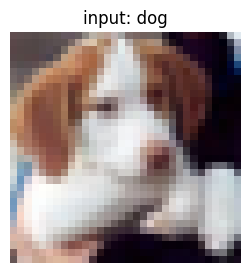

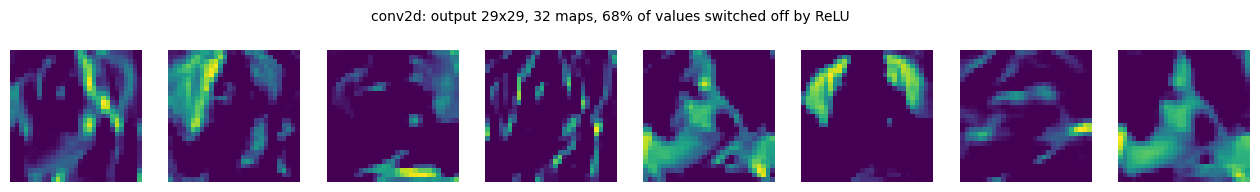

conv2d           output 29x29x32, 68% of values are zero after ReLU


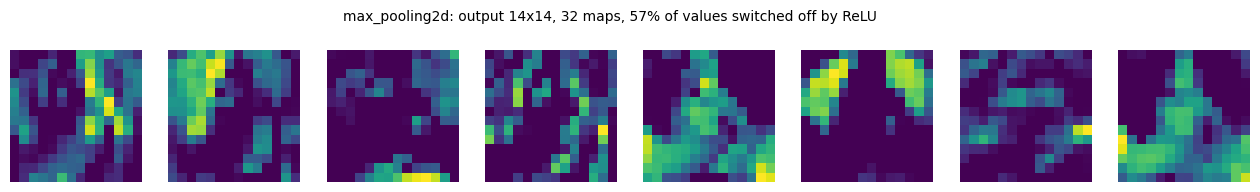

max_pooling2d    output 14x14x32, 57% of values are zero after ReLU


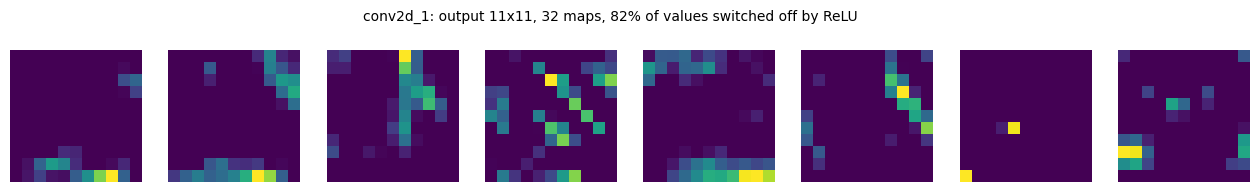

conv2d_1         output 11x11x32, 82% of values are zero after ReLU


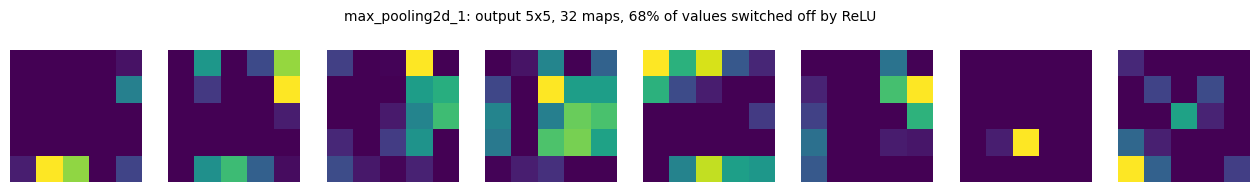

max_pooling2d_1  output 5x5x32, 68% of values are zero after ReLU


In [2]:
img = x_test[16]                                     # the module's default test image (a dog)
layer_outputs = [l.output for l in model.layers if any(k in l.name for k in ("conv", "pool"))]   # each conv and pooling layer
probe = keras.Model(inputs=model.inputs, outputs=layer_outputs)   # a model that returns every one of those layers' outputs
maps = probe.predict(img[None], verbose=0)           # run the image through; img[None] adds the batch dimension

plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis("off")   # show the input image
plt.title(f"input: {LABEL_NAMES[y_test[16][0]]}"); plt.show()  # title with the true class, and draw
for layer, fmap in zip([l for l in model.layers if any(k in l.name for k in ("conv", "pool"))], maps):   # each layer in turn
    n = min(8, fmap.shape[-1])                       # show the first 8 of its feature maps
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.2))   # one small picture per feature map
    for i in range(n):  # each feature map
        axes[i].imshow(fmap[0, :, :, i], cmap="viridis"); axes[i].axis("off")   # bright = the filter found its pattern there
    zero_share = (fmap <= 0).mean()                  # share of values that are zero (switched off by ReLU)
    fig.suptitle(f"{layer.name}: output {fmap.shape[1]}x{fmap.shape[2]}, {fmap.shape[-1]} maps, "  # layer name, size and sparsity
                 f"{zero_share:.0%} of values switched off by ReLU", fontsize=10)
    plt.show()  # draw this layer's maps
    print(f"{layer.name:<16} output {fmap.shape[1]}x{fmap.shape[2]}x{fmap.shape[-1]}, "  # the same numbers as text
          f"{zero_share:.0%} of values are zero after ReLU")

## 2. New images

**Why the pictures below look so pixelated.** CIFAR-10 images are only 32×32 pixels, and the model was trained
on nothing else. So every photo has to be cropped to a square and shrunk to 32×32 before the model can take it.
That's 1,024 pixels for the whole picture. Matplotlib then blows the tiny image back up to fit the plot, which
is why each pixel shows as a visible block. That's not a bug: it's exactly what the model gets to see. Each photo
below is shown twice, the original crop on the left and the 32×32 version the model actually sees on the right.

9 images found


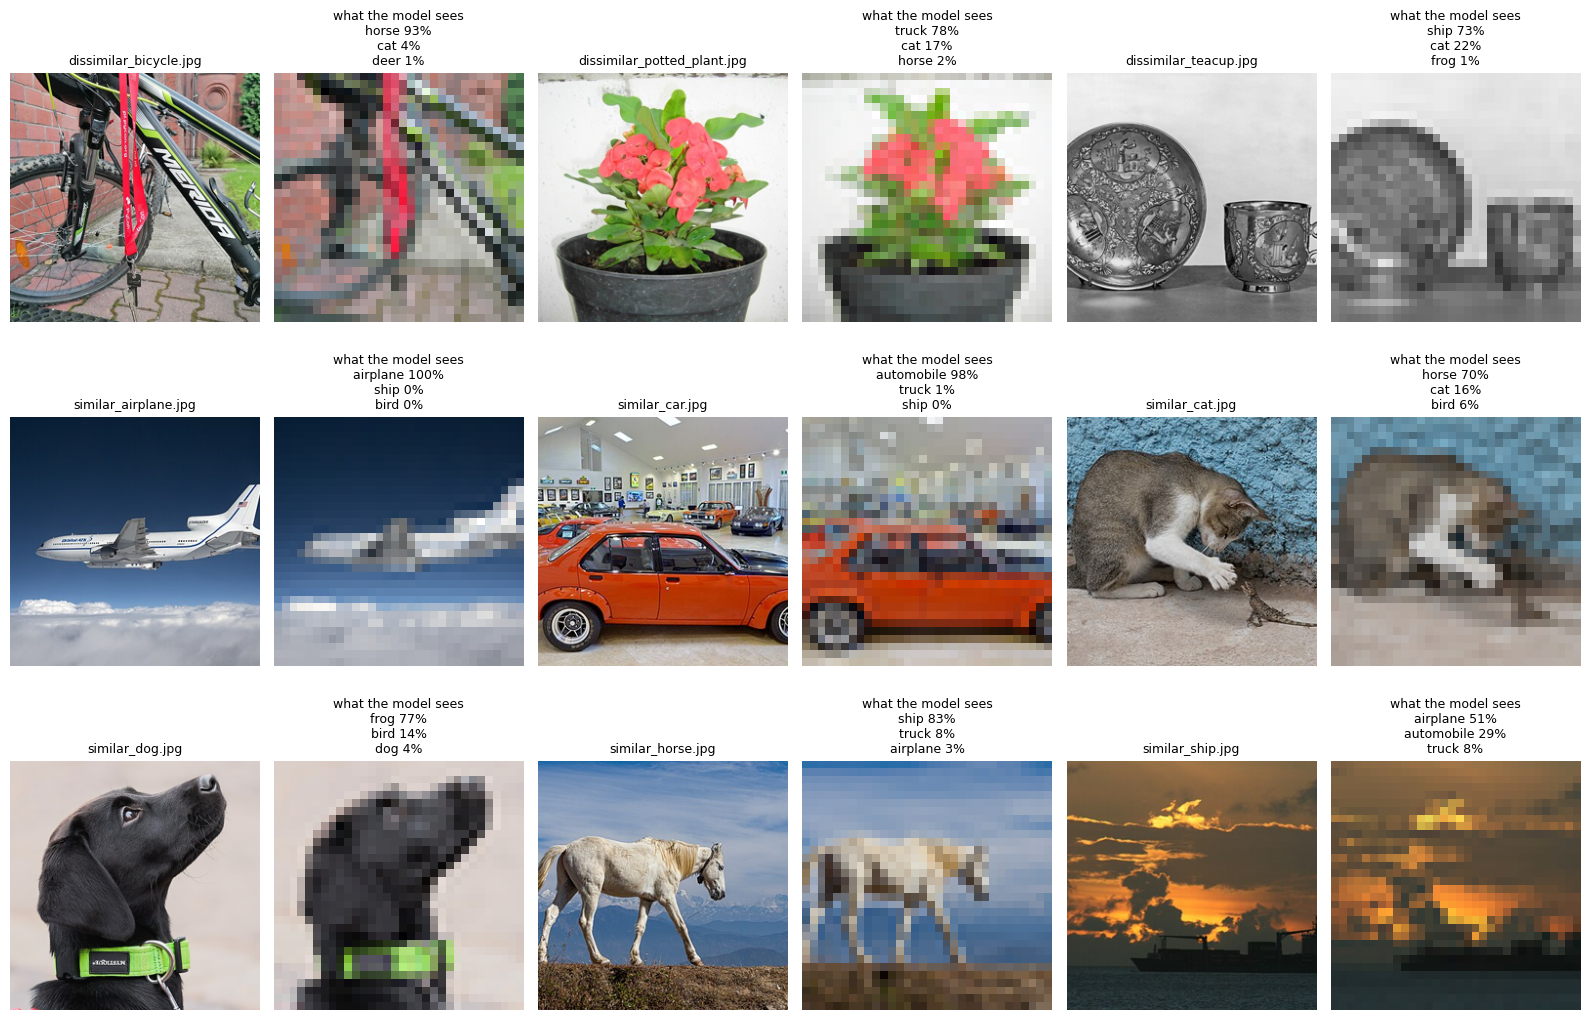

dissimilar_bicycle.jpg       top guess horse        93%   second cat           4%
dissimilar_potted_plant.jpg  top guess truck        78%   second cat          17%
dissimilar_teacup.jpg        top guess ship         73%   second cat          22%
similar_airplane.jpg         top guess airplane    100%   second ship          0%
similar_car.jpg              top guess automobile   98%   second truck         1%
similar_cat.jpg              top guess horse        70%   second cat          16%
similar_dog.jpg              top guess frog         77%   second bird         14%
similar_horse.jpg            top guess ship         83%   second truck         8%
similar_ship.jpg             top guess airplane     51%   second automobile   29%


In [3]:
paths = sorted(p for p in os.listdir("my_images") if p.lower().endswith((".jpg", ".jpeg", ".png", ".webp")))   # every image file
print(f"{len(paths)} images found")  # how many test images

def square(path):  # open a photo and crop it to a centred square
    im = Image.open(path).convert("RGB")             # open the photo as plain red/green/blue
    side = min(im.size)                              # length of the shorter edge
    left, top = (im.width - side) // 2, (im.height - side) // 2   # top-left corner of a centred square
    return im.crop((left, top, left + side, top + side))   # the square crop, still full resolution

def prepare(path):  # turn a photo into a 32x32 CIFAR-style input
    # CIFAR-10 images are 32x32 pixels, so each photo is cropped to a square and shrunk to match.
    im = square(path).resize((32, 32), Image.LANCZOS)   # crop to a square, shrink to 32x32
    return np.asarray(im) / 255.0                    # pixels scaled to 0-1, like the training data

rows = []                                            # results table
if paths:                                            # only run if there are images
    imgs = np.stack([prepare(os.path.join("my_images", p)) for p in paths])   # all images as one batch
    probs = model.predict(imgs, verbose=0)           # the model's probability for each of the 10 classes, per image
    per_row = 3                                      # 3 photos per row, each shown as a pair
    nrows = int(np.ceil(len(paths) / per_row))       # rows needed
    fig, axes = plt.subplots(nrows, 2 * per_row, figsize=(16, 3.6 * nrows), squeeze=False)  # two slots per photo
    for ax in axes.ravel(): ax.axis("off")           # hide axes, including any empty slots
    pairs = axes.reshape(nrows, per_row, 2).reshape(-1, 2)   # list of (left slot, right slot) pairs, one per photo
    for (ax_big, ax_small), name, im, p in zip(pairs, paths, imgs, probs):   # one pair per image
        top3 = np.argsort(-p)[:3]                    # the three most likely classes
        ax_big.imshow(square(os.path.join("my_images", name)).resize((256, 256)))   # the original crop, for comparison
        ax_big.set_title(name, fontsize=9)           # file name over the original
        ax_small.imshow(im, interpolation="nearest") # the 32x32 version the model actually saw, each pixel as a block
        ax_small.set_title("what the model sees\n" + "\n".join(f"{LABEL_NAMES[i]} {p[i]:.0%}" for i in top3), fontsize=9)  # top three guesses
        rows.append((name, LABEL_NAMES[top3[0]], f"{p[top3[0]]:.0%}", LABEL_NAMES[top3[1]], f"{p[top3[1]]:.0%}"))  # top two guesses for the text table
    plt.tight_layout(); plt.show()                   # tidy the spacing and draw
    for r in rows:                                   # the same results as text
        print(f"{r[0]:<28} top guess {r[1]:<11} {r[2]:>4}   second {r[3]:<11} {r[4]:>4}")  # one line per image

## What I took from it


**Inside the layers**
- Each layer shrinks the picture and makes it more abstract: 32×32 pixels in, 29×29 after the first
  convolution, 14×14 after pooling, 11×11, then 5×5. The early feature maps still look like the dog. By the
  last pooling layer they are 5×5 blobs that only the network can read.
- ReLU switches most of the network off for any one image. After the first convolution 68% of the values are
  zero, and after the second 82%. Deeper filters respond to more specific patterns, so fewer of them fire.
  That sparsity is part of what makes CNNs efficient.

**New images: things the model was trained on (2 of 6 right)**
- **The plane (100%) and the car (98%) were right.** Both are side-on, centred, on plain backgrounds, which is
  exactly how CIFAR-10 photos look.
- **The other four were wrong, and confidently.** The horse was called a ship (83%). It's a white horse against
  a big blue sky, and at 32×32 the sky outweighs the horse. The dog, a close-up of a head looking up, was called
  a frog (77%). The cat, crouched low with a lizard, was called a horse (70%). The ship, a silhouette at sunset,
  was called a plane.
- So 64% on CIFAR's own test images didn't carry over to ordinary photos. The test set comes from the same kind
  of source as the training set. Real photos have different framing, lighting and backgrounds. This is called
  distribution shift, and it's why a test score only tells you how a model does on data *like* its test set.

**New images: things it was never trained on (3 of 3 given a confident wrong label)**
- The bicycle became a horse (93%), the potted plant a truck (78%), and the teacup a ship (73%).
- The model **can't say "I don't know".** Its last layer spreads 100% of its belief across the 10 classes it
  knows, so every image gets forced into one of them, often with high confidence. Confidence here reflects how
  the probabilities are squeezed, not how sure the model should be.

**Why it matters.** A system like this, put into use, would label things it has never seen with confidence and
no warning. Fixing that takes design decisions, not just a better score: an "unknown" option, a confidence
threshold below which a human checks, and testing on images that look like real use. This links to the ethical
points in my reflection on Wall (2019).